Tested with:
- Python 3.13.9
- numpy 2.4.4
- pandas 2.3.3

In [18]:
import warnings
warnings.filterwarnings('ignore')

import pprint  # Pretty print data structures
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from mpl_toolkits.axes_grid1 import make_axes_locatable
plt.style.use('ggplot')  # Set Matplotlib style to 'ggplot'

def df_groupby(df):
    df = df.groupby('n_labeled').agg(
        mae_test=('mae_test', 'mean'),   min_mae_test=('mae_test', 'min'),   max_mae_test=('mae_test', 'max'),
        mse_test=('mse_test', 'mean'),   min_mse_test=('mse_test', 'min'),   max_mse_test=('mse_test', 'max'),
        rmse_test=('rmse_test', 'mean'), min_rmse_test=('rmse_test', 'min'), max_rmse_test=('rmse_test', 'max'),
        r2_test=('r2_test', 'mean'),     min_r2_test=('r2_test', 'min'),     max_r2_test=('r2_test', 'max'),
        mae_val=('mae_val', 'mean'),   min_mae_val=('mae_val', 'min'),   max_mae_val=('mae_val', 'max'),
        mse_val=('mse_val', 'mean'),   min_mse_val=('mse_val', 'min'),   max_mse_val=('mse_val', 'max'),
        rmse_val=('rmse_val', 'mean'), min_rmse_val=('rmse_val', 'min'), max_rmse_val=('rmse_val', 'max'),
        r2_val=('r2_val', 'mean'),     min_r2_val=('r2_val', 'min'),     max_r2_val=('r2_val', 'max'),
    ).reset_index()
    return df

def plot_al(dfs, labels, score=None, metric='rmse', dataset='qm9', save=None, ls_list=None, color_list=None, format='pdf'):
    '''
    Plot AL metrics base on labeled samples.

    Args:
        dfs : List of Data Frames modified with df_groupby (list).
        labels : List of AL strategies (list).
        score : Dictionary of metric scores of baseline model (dict).
        save : Save path (str).
        format : Save format (str).
    '''
    plt.rcParams.update({
    'text.usetex': True,
    'text.latex.preamble': r'\usepackage{amsmath}',
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'],
    'mathtext.fontset': 'cm',
    })
    if metric == 'rmse':
        metric_name = 'RMSE'
        if dataset == 'qm9':
            metrics = [('rmse_test', r'RMSE on HOMO-LUMO Gap (eV)')]
        if dataset == 'mp':
            metrics = [('rmse_test', r'RMSE on Formation Energy (eV/atom)')]
        if dataset == 'hse':
            metrics = [('rmse_test', r'RMSE on $\Delta G$ (eV/atom)')]
    if metric == 'mae':
        metric_name = 'MAE'
        if dataset == 'qm9':
            metrics = [('mae_test', r'MAE on HOMO-LUMO Gap (eV)')]
        if dataset == 'mp':
            metrics = [('mae_test', r'MAE on Formation Energy (eV/atom)')]
        if dataset == 'hse':
            metrics = [('mae_test', r'MAE on $\Delta G$ (eV/atom)')]
    if metric == 'r2':
        metric_name = 'R^2'
        metrics = [('r2_test', r'$R^2$')]
    fig, ax = plt.subplots(figsize=(6, 6))

    # Generate a color palette dynamically based on the number of dataframes
    cmap = plt.get_cmap('tab10')
    if ls_list is None:
        lines = ['-'] * len(dfs)
    else:
        lines = ls_list
    if color_list is None:
        colors = [cmap(i) for i in range(len(dfs))]
    else:
        colors = [cmap(i) for i in color_list]
    
    for (key, label) in metrics:
        # Loop through dataframes, labels, and the auto-generated colors
        for df, name, color, line in zip(dfs, labels, colors, lines):
            ax.plot(
                df['n_labeled'],
                df[key],
                color=color,
                label=name,
                linewidth=3,
                ls=line,
            )
            ax.fill_between(
                df['n_labeled'],
                df[f'min_{key}'],
                df[f'max_{key}'],
                alpha=0.2,
                color=color,
            )
        if score is not None:    
            baseline_val = score[key]
            ax.axhline(
                baseline_val,
                color='black',
                ls='-',
                linewidth=3,
                label=rf'$\mathrm{{{metric_name}}}_{{\mathrm{{full}}}}$' f' = {baseline_val:.2f}',
            )
            if key == 'rmse_test':
                ax.axhline(
                baseline_val*1.1,
                color='gray',
                ls='--',
                linewidth=3,
                label=r'$1.1 \times \mathrm{RMSE}_{\mathrm{full}}$' f' = {1.1*baseline_val:.2f}',
            )
        
        ax.set_xscale('log')
        ax.xaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=(0.7, 1.0, 2.0, 3.0, 5.0)))
        ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
        ax.xaxis.set_minor_locator(ticker.NullLocator())
        if metric == 'r2':
            ax.yaxis.set_major_locator(ticker.MultipleLocator(0.01))
        
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(ymin - (ymax - ymin) * 0.05, ymax + (ymax - ymin) * 0.05)
        ax.set_xlabel('Train size', fontsize=16, color='black')
        ax.set_ylabel(label, fontsize=16, color='black')
        ax.legend(facecolor='white', fontsize=14)
        ax.tick_params(axis='both', labelsize=14, colors='black')
    plt.tight_layout()
    if save is not None:
        fig.savefig(save, format=format, dpi=300)
    plt.show()

In [2]:
qm9_com_unc = df_groupby(pd.read_csv('com/qm9/al_history_com_qbc_gap_qm9.csv'))
qm9_com_rnd = df_groupby(pd.read_csv('com/qm9/al_history_com_rnd_gap_qm9.csv'))
qm9_com_div = df_groupby(pd.read_csv('com/qm9/al_history_com_div_gap_qm9.csv'))
qm9_schnet_unc = df_groupby(pd.read_csv('schnet/qm9/al_history_schnet_unc_gap_qm9.csv'))
qm9_schnet_rnd = df_groupby(pd.read_csv('schnet/qm9/al_history_schnet_rnd_gap_qm9.csv'))
qm9_schnet_div = df_groupby(pd.read_csv('schnet/qm9/al_history_schnet_div_gap_qm9.csv'))
mp_com_unc = df_groupby(pd.read_csv('com/matbench/al_history_com_unc_eform_matbench.csv'))
mp_com_rnd = df_groupby(pd.read_csv('com/matbench/al_history_com_rnd_eform_matbench.csv'))
mp_com_div = df_groupby(pd.read_csv('com/matbench/al_history_com_div_eform_matbench.csv'))
mp_schnet_rnd = df_groupby(pd.read_csv('schnet/matbench/al_history_schnet_rnd_eform_matbench.csv'))
mp_schnet_div = df_groupby(pd.read_csv('schnet/matbench/al_history_schnet_div_eform_matbench.csv'))
hse_com_unc = df_groupby(pd.read_csv('com/hse_df_feat/al_history_com_unc_dG_hse_df_feat.csv'))
hse_com_rnd = df_groupby(pd.read_csv('com/hse_df_feat/al_history_com_rnd_dG_hse_df_feat.csv'))
hse_com_div = df_groupby(pd.read_csv('com/hse_df_feat/al_history_com_div_dG_hse_df_feat.csv'))

#convert Eh to eV for QM9 dataset
cols = [c for c in qm9_com_rnd.columns if c not in {'n_labeled','r2_test','min_r2_test','max_r2_test','r2_val','min_r2_val','max_r2_val'}]
qm9_com_rnd[cols] = qm9_com_rnd[cols]*27.2114
qm9_com_unc[cols] = qm9_com_unc[cols]*27.2114
qm9_com_div[cols] = qm9_com_div[cols]*27.2114
qm9_schnet_unc[cols] = qm9_schnet_unc[cols]*27.2114
qm9_schnet_rnd[cols] = qm9_schnet_rnd[cols]*27.2114
qm9_schnet_div[cols] = qm9_schnet_div[cols]*27.2114

qm9_com_score = {'mae_test': 0.25711243520402216, 'rmse_test': 0.338457686166176, 'r2_test': 0.9313994999565665, 'mae_val': 0.2601916973879225, 'rmse_val': 0.34244022132827767, 'r2_val': 0.9296210906642849}
qm9_schnet_score = {'mae_test': 0.1558835741095802, 'rmse_test': 0.20676268348051294, 'r2_test': 0.9743986516325408, 'mae_val': 0.15651544069372125, 'rmse_val': 0.20822553851825815, 'r2_val': 0.9739790854865609}
mp_com_score = {'mae_test': 0.14041179882723992, 'rmse_test': 0.26777975634615525, 'r2_test': 0.9469139113302693, 'mae_val': 0.13920637633461802, 'rmse_val': 0.2619476987746565, 'r2_val': 0.949552216822522}
mp_schnet_score = {'mae_test': 0.03830213132863562, 'rmse_test': 0.07303179313567791, 'r2_test': 0.9960855207069089, 'mae_val': 0.037881501726280124, 'rmse_val': 0.07079548294256037, 'r2_val': 0.9962828794960769}
hse_com_score = {'mae_test': 0.15797230078802446, 'rmse_test': 0.24261461545794716, 'r2_test': 0.9929735360749617, 'mae_val': 0.16530167484711678, 'rmse_val': 0.2533871137739142, 'r2_val': 0.992531534734233}

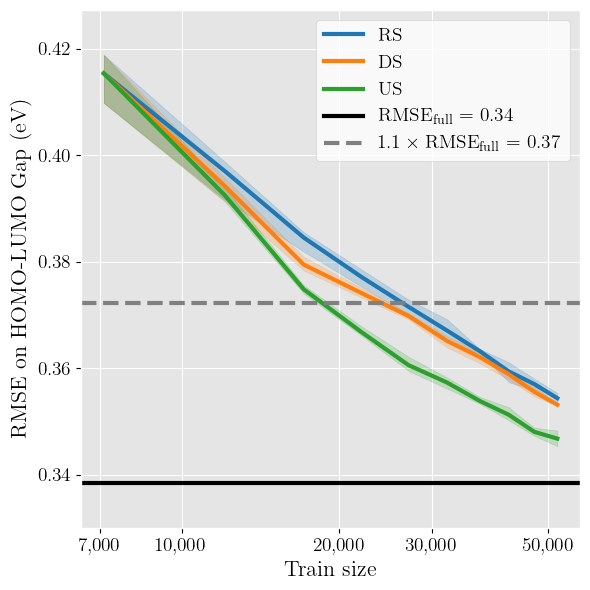

In [37]:
plot_al([qm9_com_rnd, qm9_com_div, qm9_com_unc], ['RS', 'DS', 'US'], score=qm9_com_score, metric='rmse', dataset='qm9', save='com/qm9/al_com_rmse_gap_qm9.pdf', format='pdf')

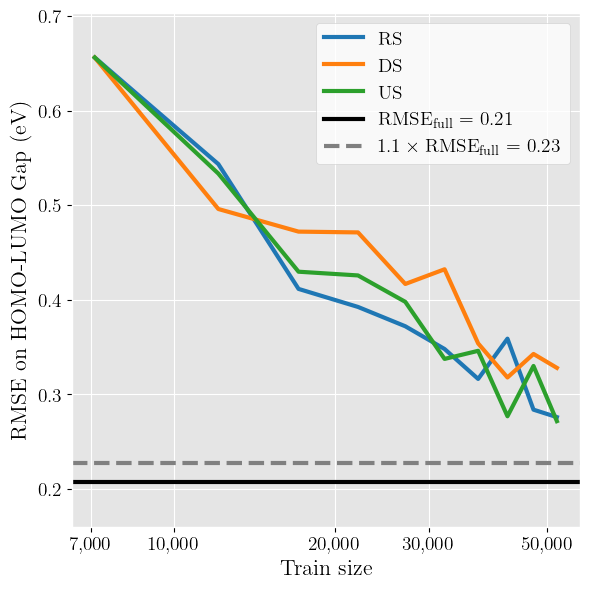

In [4]:
plot_al([qm9_schnet_rnd, qm9_schnet_div, qm9_schnet_unc], ['RS', 'DS', 'US'], score=qm9_schnet_score, metric='rmse', dataset='qm9', save='schnet/qm9/al_schnet_rmse_gap_qm9.pdf', format='pdf')

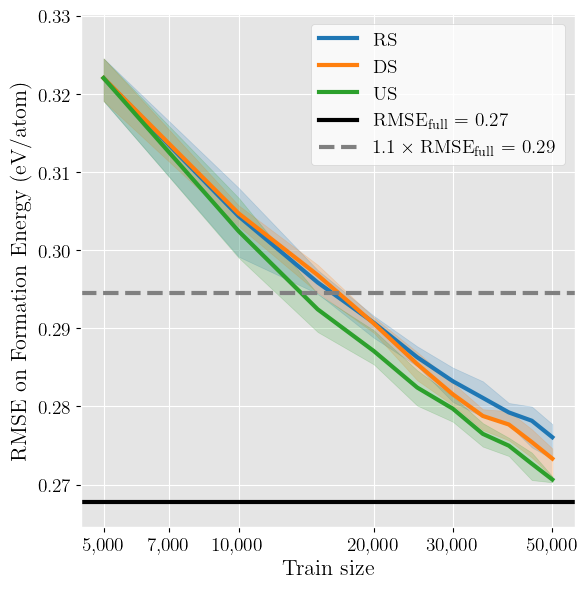

In [5]:
plot_al([mp_com_rnd, mp_com_div, mp_com_unc], ['RS', 'DS', 'US'], score=mp_com_score, metric='rmse', dataset='mp', save='com/matbench/al_com_rmse_eform_matbench.pdf', format='pdf')

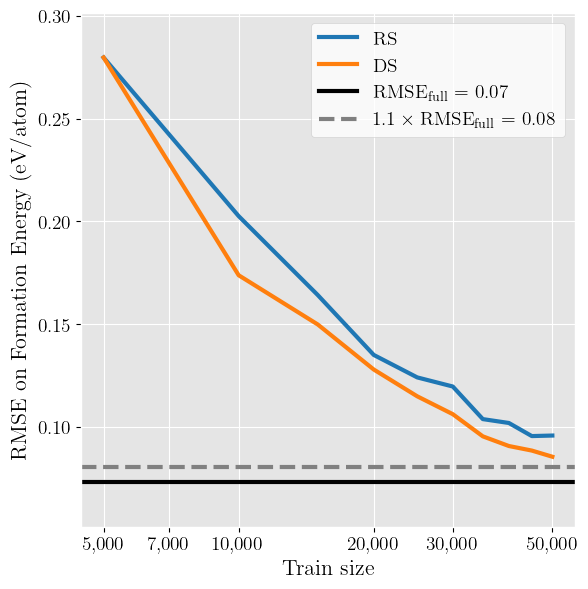

In [6]:
plot_al([mp_schnet_rnd, mp_schnet_div], ['RS', 'DS'], score=mp_schnet_score, metric='rmse', dataset='mp', save='schnet/matbench/al_schnet_rmse_eform_matbench.pdf', format='pdf')

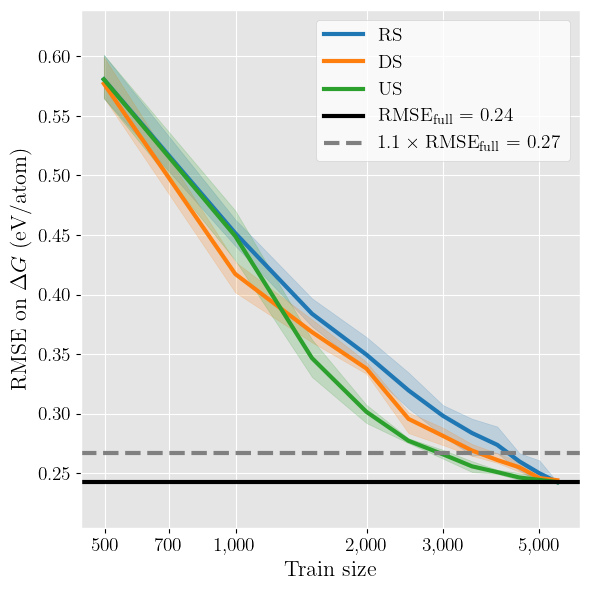

In [7]:
plot_al([hse_com_rnd, hse_com_div, hse_com_unc], ['RS', 'DS', 'US'], score=hse_com_score, metric='rmse', dataset='hse', save='com/hse_df_feat/al_com_rmse_dG_hse_df_feat.pdf', format='pdf')

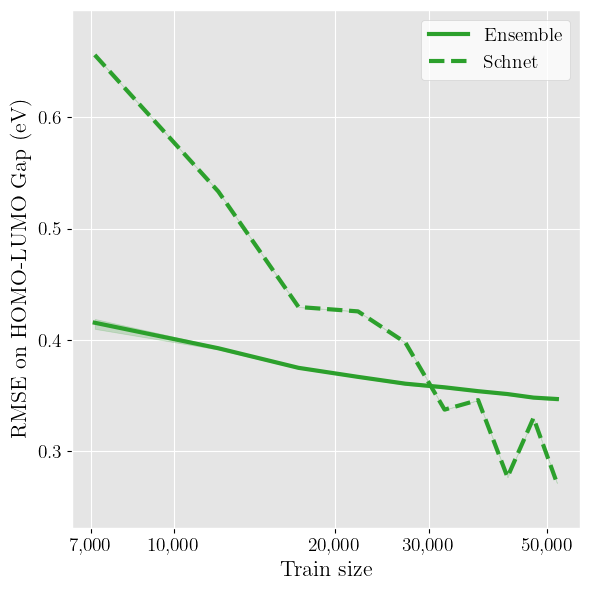

In [20]:
plot_al([qm9_com_unc, qm9_schnet_unc], ['Ensemble', 'Schnet'], score=None, metric='rmse', dataset='qm9', ls_list=['-','--'], color_list=[2,2], save='al_comparison_rmse_gap_qm9.pdf', format='pdf')

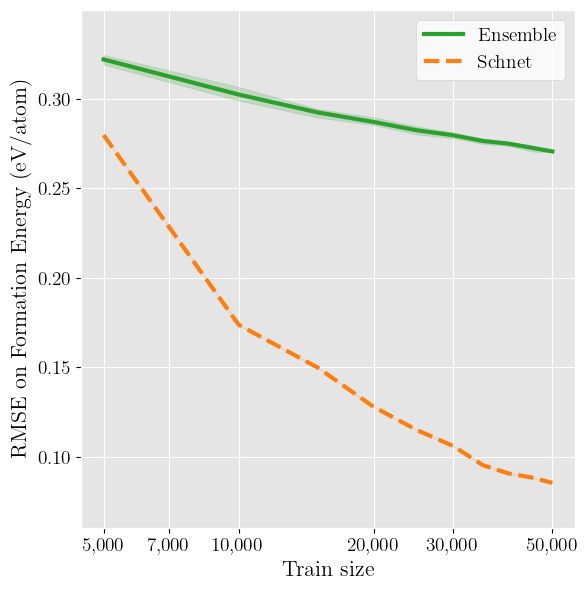

In [19]:
plot_al([mp_com_unc, mp_schnet_div], ['Ensemble', 'Schnet'], score=None, metric='rmse', dataset='mp', ls_list=['-','--'], color_list=[2,1], save='al_comparison_rmse_eform_mp.pdf', format='pdf')

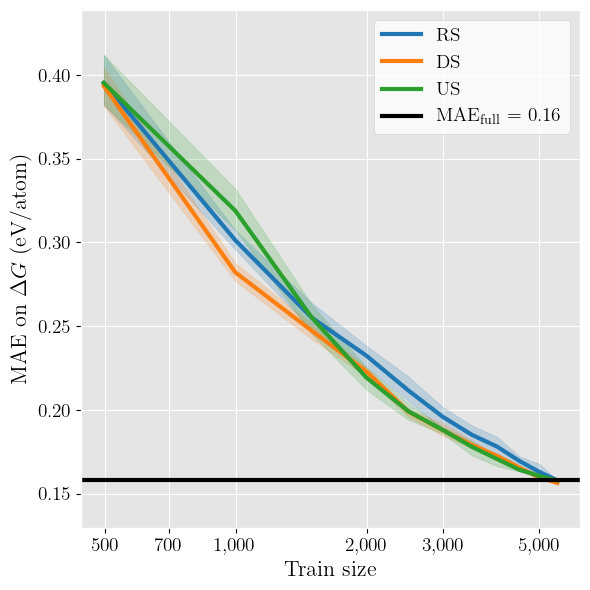

In [36]:
plot_al([hse_com_rnd, hse_com_div, hse_com_unc], ['RS', 'DS', 'US'], score=hse_com_score, metric='mae', dataset='hse')